# Respecting time order in walk-forward validation

An expanding walk-forward fold tests a later block and trains only on observations ending before a declared gap:

$$
S_k=\{a_k,\ldots,b_k\},
\qquad
T_k^{\mathrm{expand}}=\{1,\ldots,a_k-g-1\}.
$$

Here, $S_k$ is test fold $k$; $a_k$ and $b_k$ are its first and last positions; $g$ is the gap length. $T_k^{\mathrm{expand}}$ is the expanding training set; positions are written from one for clarity; $k$ indexes folds.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("16_temporal_cross_validation");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,WalkForwardCV,cv_split,backtest_predictions,filtered_training_indices_with_embargo
prefix = "walk"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
levels = log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","One-hour return","Past volatility","Log volume change","Log quote-volume change","Log trade-count change"]
public_x = hcat(returns[positions.-1],levels[positions.-1].-levels[positions.-5],[std(returns[index-16:index-1]) for index in positions],diff(log1p.(bars.Volume))[positions.-2],diff(log1p.(bars[!,"Quote volume"]))[positions.-2],diff(log1p.(bars.Trades))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
input_root = joinpath("..","data","chapter16_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
primitive = TOML.parsefile(manifest_path)["random_fold_permutation"]
permutation_path = joinpath(input_root,primitive["file"])
permutation = CSV.read(permutation_path,DataFrame).position
@assert sort(permutation)==collect(1:count_observations)
@assert nrow(bars)==2976 && size(public_x)==(2951,6)
@assert all(isfinite,public_x) && length(dates)==length(event_times)==length(public_y)
violet = "#C084FC"
split_colors = [palette.grid,palette.cyan,palette.rose,palette.amber,violet]
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter14-"*replace(name,"_"=>"-"))
end

function save_splits(key,splits)
    evidence = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(evidence,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(evidence,paths,key*"_splits")
    return nothing
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=false))
    return count(index->index∉allowed,train)
end

function split_matrix(splits)
    result = zeros(Int,length(splits),count_observations)
    for (fold,(train,test)) in enumerate(splits)
        result[fold,train] .= 1
        result[fold,test] .= 2
    end
    return result
end

function split_legend!(figure;full=false)
    labels = ["Excluded","Train","Test","Overlap removed","Embargo removed"]
    for index in 1:(full ? 5 : 3)
        plot!(figure,[NaN],[NaN];color=split_colors[index],marker=:rect,linewidth=3,label=labels[index])
    end
    plot!(figure;legend=:outerright,colorbar=false)
    return figure
end

function geometry(collections,title_text,stem)
    panels = []
    for (name,splits) in collections
        values = split_matrix(splits)
        panel = heatmap(1:count_observations,1:length(splits),values;color=cgrad(split_colors[1:3],categorical=true),clims=(-.5,2.5),colorbar=false,yflip=true,yticks=1:length(splits),ylabel="Fold",title=name,grid=false,xlims=(.5,count_observations+.5))
        push!(panels,split_legend!(panel))
    end
    plot!(panels[end];xlabel="Observation in time order")
    figure = plot(panels...;layout=(length(panels),1),size=(1300,820),plot_title=title_text,plot_titlefontsize=13,left_margin=8Plots.mm,right_margin=16Plots.mm)
    save_figure(figure,paths,stem)
    return nothing
end

function fitted_model!(records,fold,x,y;weights=ones(length(y)))
    model = BookLogisticLBFGS.fit_logistic(x,y;sample_weight=weights,C=1.,class_weight=nothing,standardize=false,tol=1e-4,max_iter=1000)
    @assert model.converged
    b = model.coefficients
    push!(records,(fold=fold,training_observations=length(y),intercept=model.intercept,b1=b[1],b2=b[2],b3=b[3],b4=b[4],b5=b[5],b6=b[6],objective=model.objective,gradient_norm=model.gradient_norm,iterations=model.iterations,converged=model.converged))
    return model
end

function score_splits(name,splits,key)
    predictions,scores = fill(NaN,count_observations),fill(NaN,count_observations)
    records,models = NamedTuple[],NamedTuple[]
    for (fold,(train,test)) in enumerate(splits)
        accuracy = NaN
        if !isempty(train) && length(unique(public_y[train]))==2
            model = fitted_model!(models,fold,public_x[train,:],public_y[train])
            predictions[test] = BookEstimators.predict(model,public_x[test,:])
            scores[test] = BookEstimators.decision_function(model,public_x[test,:])
            accuracy = mean(predictions[test].==public_y[test])
        end
        push!(records,(method=name,fold=fold,training=length(train),test=length(test),accuracy=accuracy))
    end
    result = DataFrame(records)
    rename!(result,["Method","Fold","Training observations","Test observations","Accuracy"])
    save_splits(key,splits)
    save_data(DataFrame(models),paths,key*"_fits")
    save_data(DataFrame(position=collect(1:count_observations),date=dates,actual=public_y,prediction=predictions,score=scores),paths,key*"_predictions")
    save_data(result,paths,key*"_fold_scores")
    return result,predictions
end

function score_summary(frame;with_count=false)
    records = NamedTuple[]
    for name in unique(frame.Method)
        values = filter(isfinite,frame[frame.Method.==name,"Accuracy"])
        push!(records,(method=name,count=length(values),mean=mean(values),spread=std(values),minimum=minimum(values),maximum=maximum(values)))
    end
    result = DataFrame(records)
    rename!(result,["Method","Scored folds","Mean accuracy","Accuracy spread","Minimum accuracy","Maximum accuracy"])
    return with_count ? result : select(result,Not("Scored folds"))
end


score_summary (generic function with 1 method)

## Comparing expanding windows with rolling windows

Row,Method,Fold,Training observations,Test observations,Training begins,Training ends,Test begins,Test ends
,String,Int64,Int64,Int64,String,String,String,String
1,"Expanding, no gap",1,0,492,Not available,Not available,2021-01-01 04:15:00,2021-01-06 07:00:00
2,"Expanding, no gap",2,492,492,2021-01-01 04:15:00,2021-01-06 07:00:00,2021-01-06 07:15:00,2021-01-11 10:00:00
3,"Expanding, no gap",3,984,492,2021-01-01 04:15:00,2021-01-11 10:00:00,2021-01-11 10:15:00,2021-01-16 13:00:00
4,"Expanding, no gap",4,1476,492,2021-01-01 04:15:00,2021-01-16 13:00:00,2021-01-16 13:15:00,2021-01-21 16:00:00
5,"Expanding, no gap",5,1968,492,2021-01-01 04:15:00,2021-01-21 16:00:00,2021-01-21 16:15:00,2021-01-26 19:00:00
6,"Expanding, no gap",6,2460,491,2021-01-01 04:15:00,2021-01-26 19:00:00,2021-01-26 19:15:00,2021-01-31 21:45:00
7,"Expanding, eight-bar gap",1,0,492,Not available,Not available,2021-01-01 04:15:00,2021-01-06 07:00:00
8,"Expanding, eight-bar gap",2,484,492,2021-01-01 04:15:00,2021-01-06 05:00:00,2021-01-06 07:15:00,2021-01-11 10:00:00
9,"Expanding, eight-bar gap",3,976,492,2021-01-01 04:15:00,2021-01-11 08:00:00,2021-01-11 10:15:00,2021-01-16 13:00:00


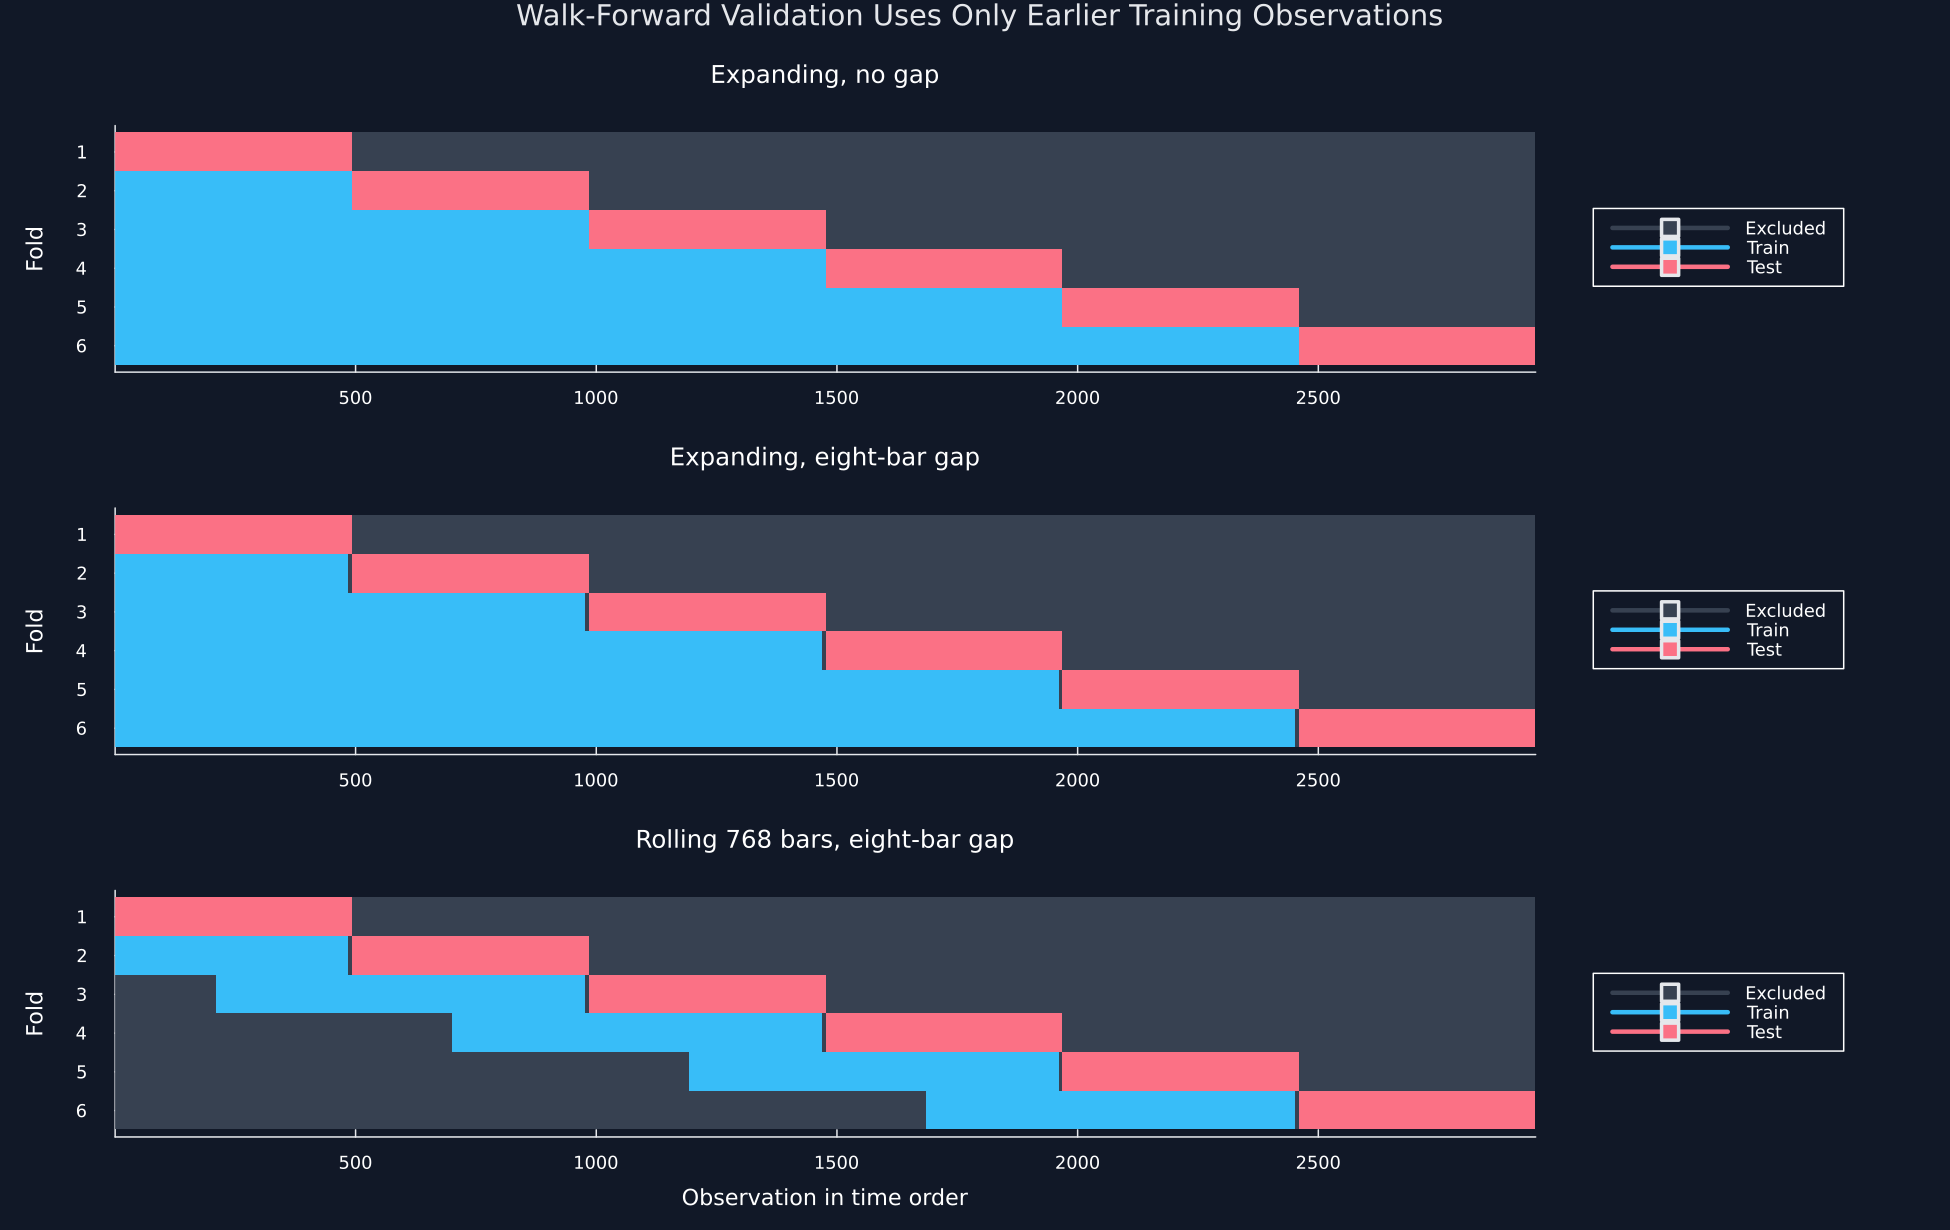

In [2]:
n_splits = 6
walk_rules = [("Expanding, no gap",WalkForwardCV(n_splits;gap=0)),("Expanding, eight-bar gap",WalkForwardCV(n_splits;gap=8)),("Rolling 768 bars, eight-bar gap",WalkForwardCV(n_splits;max_train_size=768,gap=8))]
walk_splits = Dict(name=>cv_split(rule,count_observations) for (name,rule) in walk_rules)
walk_records = NamedTuple[]
for (name,_) in walk_rules, (fold,(train,test)) in enumerate(walk_splits[name])
    push!(walk_records,(method=name,fold=fold,training=length(train),test=length(test),training_begins=isempty(train) ? "Not available" : format_time(dates[first(train)]),training_ends=isempty(train) ? "Not available" : format_time(dates[last(train)]),test_begins=format_time(dates[first(test)]),test_ends=format_time(dates[last(test)])))
end
walk_forward_windows = DataFrame(walk_records)
rename!(walk_forward_windows,["Method","Fold","Training observations","Test observations","Training begins","Training ends","Test begins","Test ends"])
table(walk_forward_windows,"walk_forward_windows","Expanding and rolling walk-forward windows on the public data.")
geometry([(name,walk_splits[name]) for (name,_) in walk_rules],"Walk-Forward Validation Uses Only Earlier Training Observations","walk_forward_geometry")


A rolling walk-forward fold keeps at most the most recent $M$ eligible observations before the gap:

$$
T_k^{\mathrm{roll}}
=\{\max(1,a_k-g-M),\ldots,a_k-g-1\}.
$$

Here, $T_k^{\mathrm{roll}}$ is the rolling training set; $a_k$ is the first test position; $g$ is the gap. $M$ is the maximum training size; $k$ indexes folds; $\max$ prevents the lower endpoint from preceding the sample.

## Time-Order Audit

In [3]:
comparison_splits = [("Random folds",cv_split(KFoldCV(n_splits;shuffle=true,random_seed=14),count_observations;permutation)),("Ordered folds",cv_split(KFoldCV(n_splits),count_observations)),("Purged folds",cv_split(PurgedKFoldCV(n_splits,dates,event_times;embargo=.01))),("Walk-forward with eight-bar gap",walk_splits["Expanding, eight-bar gap"])]
order_records = NamedTuple[]
for ((method,splits),key) in zip(comparison_splits,["random","ordered","purged","walk"])
    save_splits("order_"*key,splits)
    for (fold,(train,test)) in enumerate(splits)
        first_test = minimum(test)
        earlier_train = filter(<(first_test),train)
        crossing = count(>=(dates[first_test]),event_times[earlier_train])
        push!(order_records,(method=method,fold=fold,not_earlier=count(>=(first_test),train),crossing=crossing))
    end
end
time_order_by_fold = DataFrame(order_records)
rename!(time_order_by_fold,["Method","Fold","Training rows on or after first test row","Earlier training labels reaching test start"])
save_data(time_order_by_fold,paths,"time_order_by_fold")
time_order_audit = combine(groupby(time_order_by_fold,:Method;sort=false),"Training rows on or after first test row"=>mean=>"Mean non-earlier training rows","Training rows on or after first test row"=>maximum=>"Maximum non-earlier training rows","Earlier training labels reaching test start"=>mean=>"Mean labels crossing test start","Earlier training labels reaching test start"=>maximum=>"Maximum labels crossing test start")
table(time_order_audit,"time_order_audit","Time-order and label-end checks across validation rules.")


Row,Method,Mean non-earlier training rows,Maximum non-earlier training rows,Mean labels crossing test start,Maximum labels crossing test start
,String,Float64,Int64,Float64,Int64
1,Random folds,2455.17,2459,3.16667,8
2,Ordered folds,1229.17,2459,6.66667,8
3,Purged folds,1198.33,2422,0.0,0
4,Walk-forward with eight-bar gap,0.0,0,0.0,0


Walk-forward error is the test-size-weighted average of losses from folds that have a usable training history:

$$
\widehat R_{\mathrm{WF}}
=\frac{\sum_{k\in\mathcal K_+}|S_k|R_k}
{\sum_{k\in\mathcal K_+}|S_k|},
\qquad
R_k=\frac1{|S_k|}\sum_{i\in S_k}
\one\!\left\{\widehat y_i\neq y_i\right\}.
$$

Here, $\mathcal K_+$ is the set of folds with training data; $S_k$ is test fold $k$; $|S_k|$ is its size. $R_k$ is fold error; $y_i$ and $\widehat y_i$ are observed and predicted labels; $\widehat R_{\mathrm{WF}}$ is combined error.

## Public Walk-Forward Results

Row,Method,Scored folds,Mean accuracy,Accuracy spread,Minimum accuracy,Maximum accuracy
,String,Int64,Float64,Float64,Float64,Float64
1,"Expanding, no gap",5,0.500205,0.0226383,0.461382,0.520325
2,"Expanding, eight-bar gap",5,0.501019,0.0229963,0.461382,0.520325
3,"Rolling 768 bars, eight-bar gap",5,0.508742,0.0135883,0.49187,0.528455


Row,Training window,Gap in bars,Scored observations,Mean training observations,Accuracy
,String,Int64,Int64,Float64,Float64
1,Expanding,0,2459,1476.0,0.500203
2,Expanding,4,2459,1472.0,0.50061
3,Expanding,8,2459,1468.0,0.501017
4,Expanding,16,2459,1460.0,0.501423
5,Rolling 384 bars,0,2459,384.0,0.493697
6,Rolling 384 bars,4,2459,384.0,0.491663
7,Rolling 384 bars,8,2459,384.0,0.49451
8,Rolling 384 bars,16,2459,384.0,0.487597
9,Rolling 768 bars,0,2459,712.8,0.50793


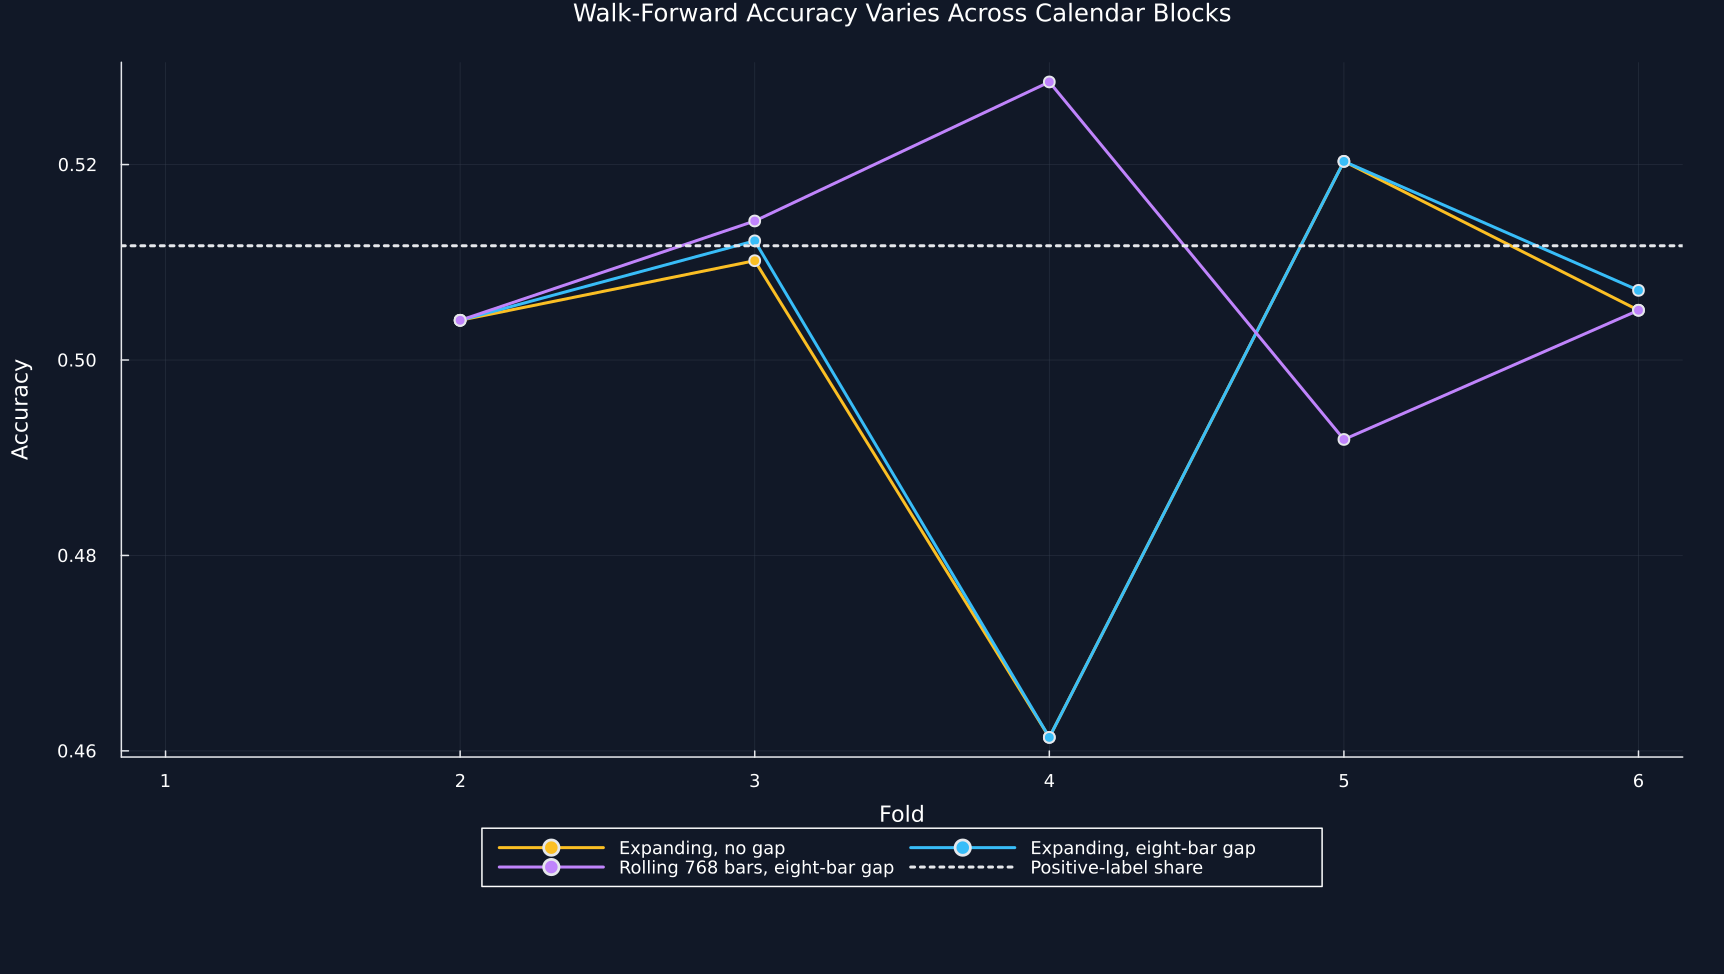

In [4]:
walk_score_frames,walk_predictions = DataFrame[],Dict{String,Vector{Float64}}()
for (index,(name,_)) in enumerate(walk_rules)
    scores,predictions = score_splits(name,walk_splits[name],"walk_rule_"*string(index))
    push!(walk_score_frames,scores)
    walk_predictions[name] = predictions
end
walk_fold_scores = vcat(walk_score_frames...)
walk_score_summary = score_summary(walk_fold_scores;with_count=true)
table(walk_score_summary,"walk_forward_accuracy","Public walk-forward accuracy for expanding and rolling training windows.")
gap_records = NamedTuple[]
for maximum in [nothing,384,768], gap in [0,4,8,16]
    name = isnothing(maximum) ? "Expanding" : "Rolling "*string(maximum)*" bars"
    splits = cv_split(WalkForwardCV(n_splits;max_train_size=maximum,gap),count_observations)
    key = "gap_"*(isnothing(maximum) ? "expanding" : string(maximum))*"_"*string(gap)
    scores,predictions = score_splits(name,splits,key)
    valid = isfinite.(predictions)
    push!(gap_records,(window=name,gap=gap,observations=count(valid),training=mean(scores[scores[!,"Training observations"].>0,"Training observations"]),accuracy=mean(public_y[valid].==predictions[valid])))
end
gap_window_sensitivity = DataFrame(gap_records)
rename!(gap_window_sensitivity,["Training window","Gap in bars","Scored observations","Mean training observations","Accuracy"])
table(gap_window_sensitivity,"gap_window_sensitivity","Sensitivity of public walk-forward accuracy to the gap and training-window length.")
save_data(walk_fold_scores,paths,"walk_forward_accuracy")
figure = plot(;title="Walk-Forward Accuracy Varies Across Calendar Blocks",xlabel="Fold",ylabel="Accuracy",xticks=1:6,size=(1150,650),legend=:outerbottom,legendcolumns=2)
for ((name,_),color) in zip(walk_rules,[palette.amber,palette.cyan,violet])
    selected = walk_fold_scores[walk_fold_scores.Method.==name,:]
    plot!(figure,selected.Fold,selected.Accuracy;marker=:circle,color,label=name)
end
hline!(figure,[mean(public_y)];color=palette.text,linestyle=:dot,label="Positive-label share")
save_figure(figure,paths,"walk_forward_accuracy")


## Tests

In [5]:
@assert size(walk_forward_windows)==(18,8)
@assert all(==(0),walk_forward_windows[walk_forward_windows.Fold.==1,"Training observations"])
@assert all(>(0),walk_forward_windows[walk_forward_windows.Fold.>1,"Training observations"])
@assert size(time_order_by_fold)==(24,4)
walk_audit = only(eachrow(time_order_audit[time_order_audit.Method.=="Walk-forward with eight-bar gap",:]))
@assert walk_audit["Maximum non-earlier training rows"]==0
@assert walk_audit["Maximum labels crossing test start"]==0
@assert only(time_order_audit[time_order_audit.Method.=="Purged folds","Maximum labels crossing test start"])==0
@assert only(time_order_audit[time_order_audit.Method.=="Purged folds","Maximum non-earlier training rows"])>0
@assert size(walk_fold_scores)==(18,5)
@assert all(value->0<=value<=1,filter(isfinite,walk_fold_scores.Accuracy))
@assert all(==(5),walk_score_summary[!,"Scored folds"])
@assert size(gap_window_sensitivity)==(12,5)
@assert all(value->0<=value<=1,gap_window_sensitivity.Accuracy)
@assert all(isnan,walk_predictions["Expanding, eight-bar gap"][walk_splits["Expanding, eight-bar gap"][1][2]])
@assert isfile(joinpath(paths.figures,"walk_forward_geometry.pdf"))
@assert isfile(joinpath(paths.figures,"walk_forward_accuracy.pdf"))
@assert isfile(joinpath(paths.tables,"walk_forward_windows.tex"))
@assert isfile(joinpath(paths.tables,"time_order_audit.tex"))
@assert isfile(joinpath(paths.tables,"walk_forward_accuracy.tex"))
@assert isfile(joinpath(paths.tables,"gap_window_sensitivity.tex"))
